Clean Fimo Vs. Original Redundant FIMO

In [1]:
import pandas as pd

#Importing and parsing clean fimo
clean_gff = pd.read_csv(
    "/Users/avery/fimo_collapsed_with_metadata.csv"
)

def extract_alias(attr):
    for field in attr.split(";"):
        if field.startswith("Alias="):
            return field.split("=")[1]
    return None

clean_gff["Alias"] =clean_gff["attributes"].apply(extract_alias)
clean_gff["sequence_id"] = clean_gff["seqid"].astype(str).str.strip()

# Importing and parsing redundant fimo
redundant_gff = pd.read_csv(
    "/Users/avery/Downloads/fimo.gff",
    sep="\t",
    comment="#",
    header=None,
    names=["seqid", "source", "type", "start", "end",
           "score", "strand", "phase", "attributes"]
)

redundant_gff["Alias"] = redundant_gff["attributes"].apply(extract_alias)
redundant_gff["sequence_id"] = redundant_gff["seqid"].astype(str).str.strip()


In [4]:
# Get unique ACR IDs from both files
clean_ids = set(clean_gff["sequence_id"].dropna().unique())
redundant_ids = set(redundant_gff["sequence_id"].dropna().unique())

# Compare IDs
print("Unique ACR IDs in clean file:", len(clean_ids))
print("Unique ACR IDs in redundant file:", len(redundant_ids))

print("Same ACR IDs:", clean_ids == redundant_ids)

# Find differences
only_clean = clean_ids - redundant_ids
only_redundant = redundant_ids - clean_ids

print("ACRs only in clean file:", len(only_clean))
print("ACRs only in redundant file:", len(only_redundant))

# Display examples if any differ
print("\nExamples only in clean file:", list(only_clean)[:10])
print("Examples only in redundant file:", list(only_redundant)[:10])

Unique ACR IDs in clean file: 19033
Unique ACR IDs in redundant file: 19033
Same ACR IDs: True
ACRs only in clean file: 0
ACRs only in redundant file: 0

Examples only in clean file: []
Examples only in redundant file: []


In [2]:
functional_groups = {
    'Chromatin & Development': ['BPC1', 'BPC5', 'BPC6'],
    'Inflorescence Development': ['RAMOSA1'],
    'Circadian & Flowering': ['CDF5'],
    'Multifunctional DOF Regulation': ['DOF3.6', 'DOF5.1', 'DOF3.4', 'DOF1.5'],
    'Vascular Development': ['DOF5.8'],
    'Cell Cycle & DNA Replication': ['E2FD', 'E2FE'],
    'Environmental Response': ['DREB2D', 'ERF095'],
    'Stress, Hormone & Defense': ['ERF014', 'ERF057', 'ERF091', 'ERF104', 'ERF2', 'ERF5'],
    'Biotic Response & Defense': ['ERF9'],
    'Abiotic Stress & ABA': ['RAP2-6'],
    'Leaf & Organ Development': ['AS2'],
    'Organ Development': ['LOB'],
    'Floral & Reproductive Development': ['AGL6'],
    'Function Uncertain': ['AT4G12670'],
    'Telomere Regulation': ['TRP1', 'TRP2'],
    'Phloem Development': ['NAC020'],
    'Fruit Maturation /  Uncertain': ['NAC058'],
    'Growth & Cell Proliferation': ['TCP14']
}


DATASET: Clean
Count matrix: (19033, 28)
TF-IDF matrix: (19033, 28)

Count cluster sizes:
0    2700
1    4616
2    5076
3    4684
4    1957
Name: count, dtype: int64

TF-IDF cluster sizes:
0    4494
1    4543
2    4682
3    1838
4    3476
Name: count, dtype: int64


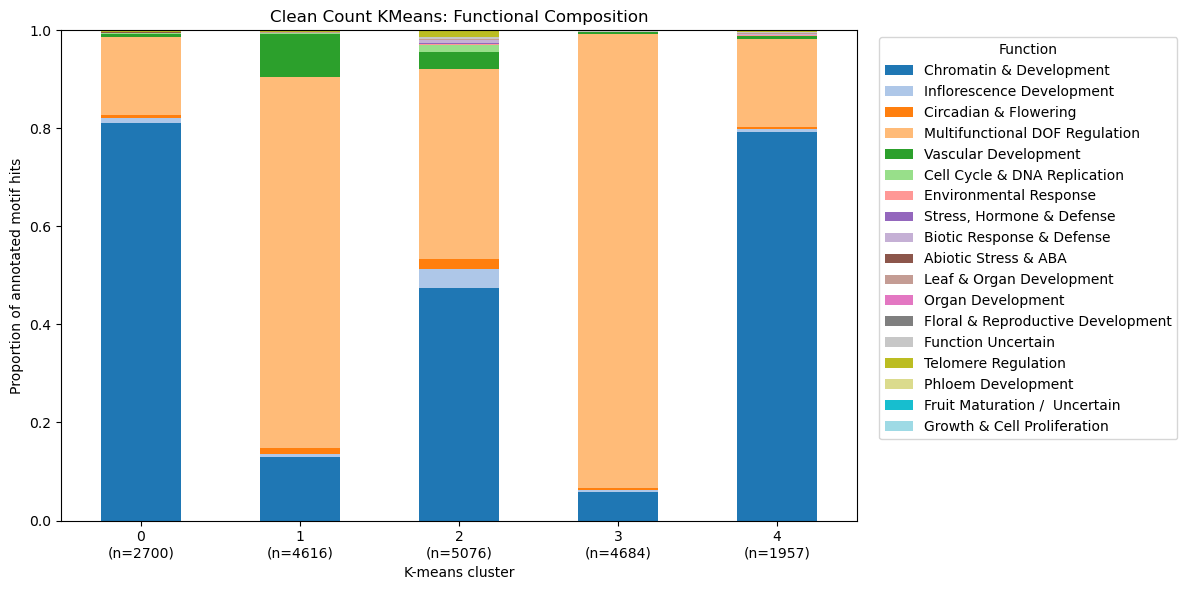

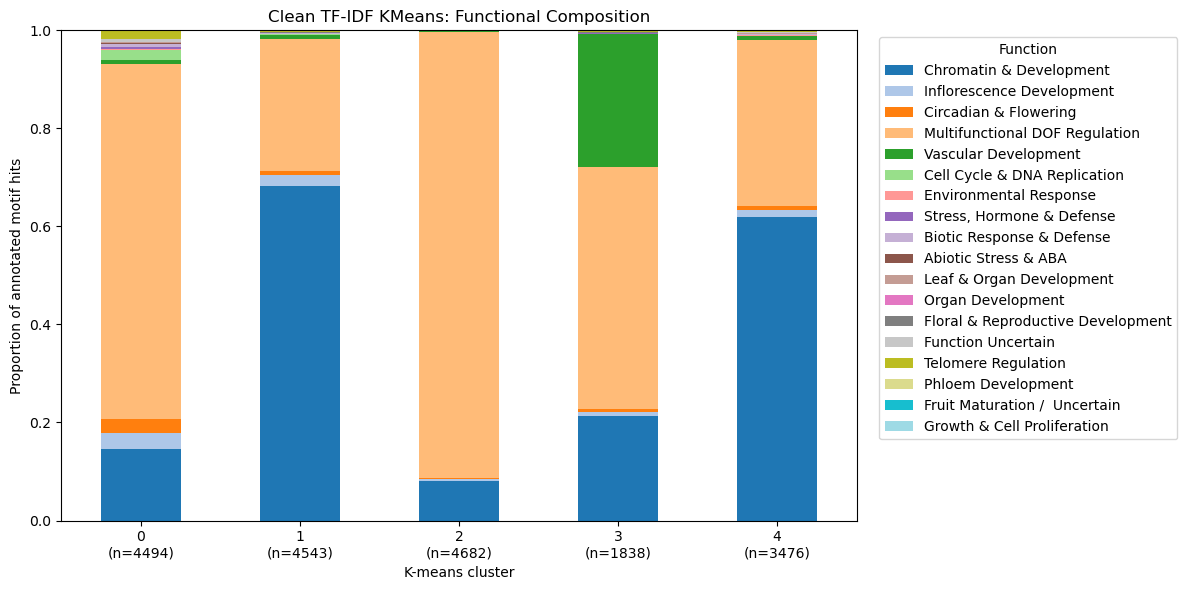


DATASET: Redundant
Count matrix: (19033, 31)
TF-IDF matrix: (19033, 31)

Count cluster sizes:
0    1989
1    6897
2    3656
3     989
4    5502
Name: count, dtype: int64

TF-IDF cluster sizes:
0    3402
1    4720
2    2213
3    4019
4    4679
Name: count, dtype: int64


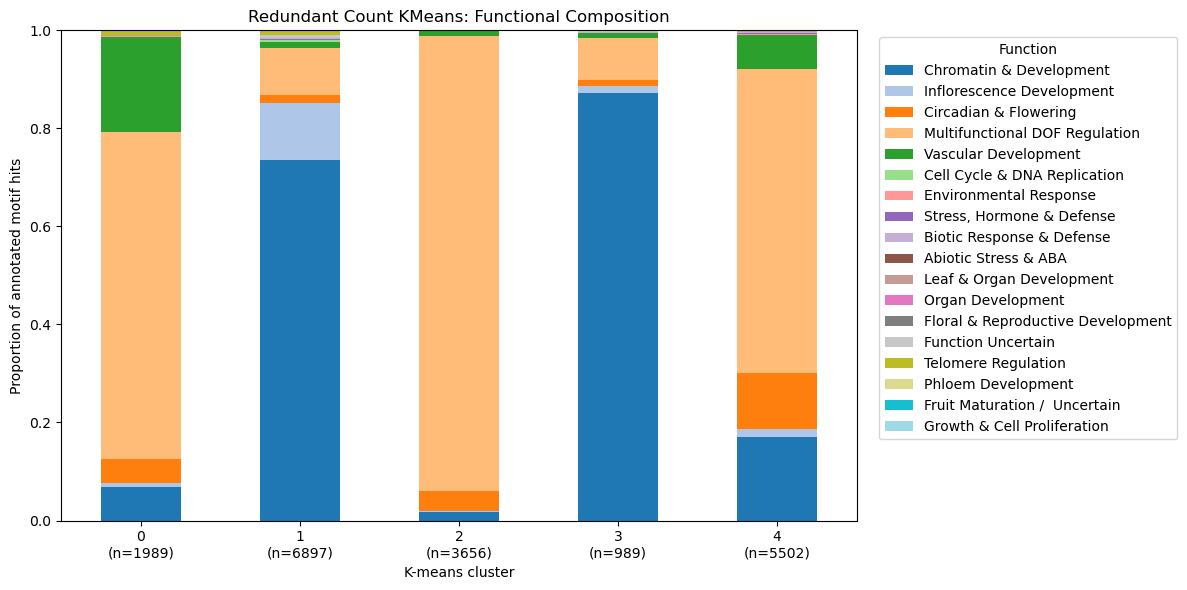

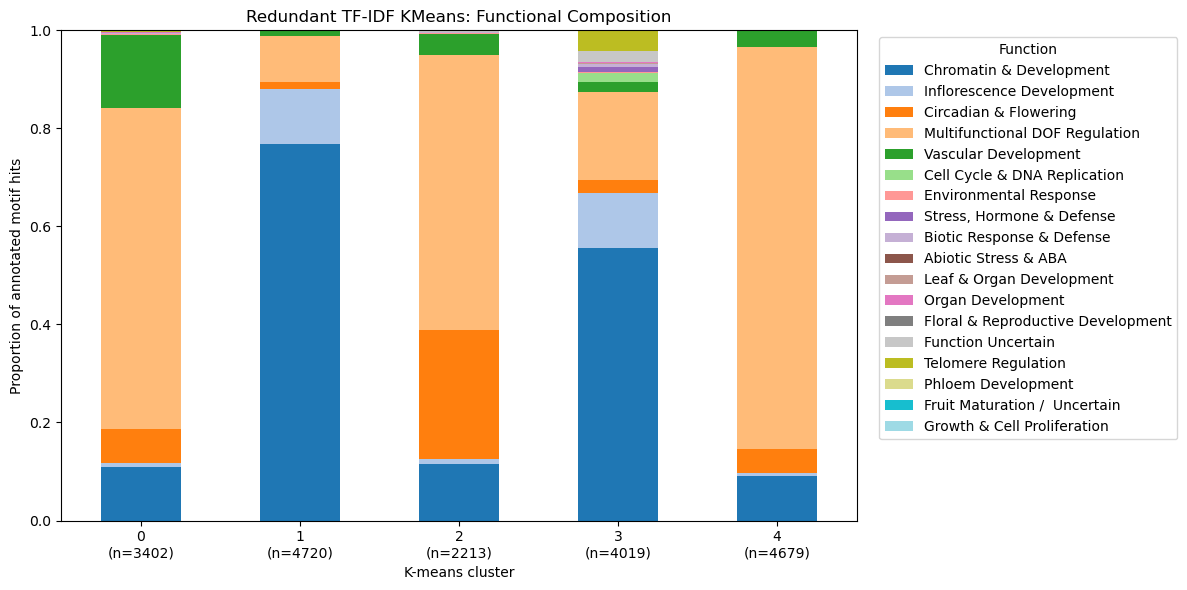

Results saved to Downloads.

KMEANS METRICS COMPARISON
  Dataset Representation Method  Clusters  Largest Cluster  Smallest Cluster  Silhouette  Calinski-Harabasz  Davies-Bouldin  ARI Stability
    Clean          Count KMeans         5             5076              1957    0.364656        6591.562547        1.514860       0.706637
    Clean         TF-IDF KMeans         5             4682              1838    0.375835        5182.915283        1.465450       0.796189
Redundant          Count KMeans         5             6897               989    0.343087        6914.919975        1.195878       0.901369
Redundant         TF-IDF KMeans         5             4720              2213    0.306272        5668.465200        1.566814       0.830044

BIOLOGICAL SUMMARY
  Dataset Representation  Cluster  Cluster Size (ACRs)  Annotated Motif Hits  Chi-square p  Shannon Diversity Index                 Top Function 1  Top 1 (%)                 Top Function 2  Top 2 (%)                 Top Function 3

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score
)
from scipy.stats import chi2_contingency, entropy

##########################################################
# FUNCTION ANNOTATION
##########################################################

alias_to_function = {
    motif: function
    for function, motifs in functional_groups.items()
    for motif in motifs
}

all_functions = list(functional_groups.keys())


##########################################################
# KMEANS STABILITY
##########################################################

def kmeans_stability(X, n_clusters=5, runs=10):

    label_sets = []

    for seed in range(runs):
        labels = KMeans(
            n_clusters=n_clusters,
            random_state=seed,
            n_init=10
        ).fit_predict(X)

        label_sets.append(labels)

    ari_scores = []

    for i in range(runs):
        for j in range(i + 1, runs):
            ari_scores.append(
                adjusted_rand_score(
                    label_sets[i],
                    label_sets[j]
                )
            )

    return np.mean(ari_scores)


##########################################################
# CLUSTER EVALUATION METRICS
##########################################################

def evaluate_clusters(X, labels, representation, dataset):

    cluster_sizes = pd.Series(labels).value_counts()

    return {
        "Dataset": dataset,
        "Representation": representation,
        "Method": "KMeans",
        "Clusters": len(cluster_sizes),
        "Largest Cluster": cluster_sizes.max(),
        "Smallest Cluster": cluster_sizes.min(),
        "Silhouette": silhouette_score(X, labels),
        "Calinski-Harabasz": calinski_harabasz_score(
            X, labels
        ),
        "Davies-Bouldin": davies_bouldin_score(
            X, labels
        ),
        "ARI Stability": kmeans_stability(
            X, n_clusters=5, runs=10
        )
    }


##########################################################
# PLOT FUNCTIONAL COMPOSITION
##########################################################

def plot_stacked(proportions, cluster_sizes, title):

    ax = proportions.plot(
        kind="bar",
        stacked=True,
        figsize=(12, 6),
        colormap="tab20"
    )

    labels = [
        f"{cluster}\n(n={cluster_sizes.loc[cluster]})"
        for cluster in proportions.index
    ]

    ax.set_xticklabels(labels, rotation=0)
    ax.set_ylabel("Proportion of annotated motif hits")
    ax.set_xlabel("K-means cluster")
    ax.set_title(title)
    ax.set_ylim(0, 1)

    ax.legend(
        title="Function",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()


##########################################################
# BIOLOGICAL SUMMARY
##########################################################

def biological_summary(
    gff_data, cluster_map, cluster_sizes, dataset, representation
):

    temp = gff_data.copy()

    temp["cluster"] = temp["sequence_id"].map(cluster_map)

    temp = temp.dropna(subset=["Function", "cluster"])

    counts = pd.crosstab(
        temp["cluster"],
        temp["Function"]
    ).reindex(
        index=cluster_sizes.index,
        columns=all_functions,
        fill_value=0
    )

    # Chi-square test of functional-group distribution
    chi_counts = counts.loc[:, counts.sum(axis=0) > 0]

    if chi_counts.shape[0] >= 2 and chi_counts.shape[1] >= 2:
        chi2, p, dof, expected = chi2_contingency(chi_counts)
        p_value = p
    else:
        p_value = np.nan

    # Functional proportions within each cluster
    proportions = counts.div(
        counts.sum(axis=1).replace(0, np.nan),
        axis=0
    ).fillna(0)

    rows = []

    for cluster in cluster_sizes.index:

        top3 = (
            proportions.loc[cluster]
            .sort_values(ascending=False)
            .head(3)
        )

        top_functions = list(top3.items())

        while len(top_functions) < 3:
            top_functions.append(("N/A", 0.0))

        shannon = entropy(
            proportions.loc[cluster].values,
            base=2
        )

        rows.append({
            "Dataset": dataset,
            "Representation": representation,
            "Cluster": cluster,
            "Cluster Size (ACRs)": int(
                cluster_sizes.loc[cluster]
            ),
            "Annotated Motif Hits": int(
                counts.loc[cluster].sum()
            ),
            "Chi-square p": p_value,
            "Shannon Diversity Index": round(shannon, 3),
            "Top Function 1": top_functions[0][0],
            "Top 1 (%)": round(top_functions[0][1] * 100, 2),
            "Top Function 2": top_functions[1][0],
            "Top 2 (%)": round(top_functions[1][1] * 100, 2),
            "Top Function 3": top_functions[2][0],
            "Top 3 (%)": round(top_functions[2][1] * 100, 2)
        })

    return pd.DataFrame(rows), proportions


##########################################################
# RUN COMPLETE ANALYSIS ON ONE GFF DATASET
##########################################################

def run_analysis(gff_data, dataset_name):

    gff_data = gff_data.copy()

    # Extract aliases and standardize ACR IDs
    gff_data["Alias"] = gff_data["attributes"].apply(
        extract_alias
    )

    gff_data["sequence_id"] = (
        gff_data["seqid"].astype(str).str.strip()
    )

    gff_data["Function"] = gff_data["Alias"].map(
        alias_to_function
    )

    gff_data = gff_data.dropna(subset=["Alias"])

    ######################################################
    # COUNT MATRIX: ACR x CRE ALIAS
    ######################################################

    count_raw = pd.crosstab(
        gff_data["sequence_id"],
        gff_data["Alias"]
    )

    # L1-normalize each ACR's motif counts
    X_count = pd.DataFrame(
        normalize(count_raw, norm="l1", axis=1),
        index=count_raw.index,
        columns=count_raw.columns
    )

    ######################################################
    # TF-IDF MATRIX: ACR DOCUMENTS, CRE ALIAS TERMS
    ######################################################

    documents = (
        gff_data.groupby("sequence_id")["Alias"]
        .apply(lambda aliases: " ".join(aliases))
    )

    vectorizer = TfidfVectorizer(
        lowercase=False,
        token_pattern=r"(?u)\b\S+\b"
    )

    tfidf_matrix = vectorizer.fit_transform(documents)

    X_tfidf = pd.DataFrame(
        tfidf_matrix.toarray(),
        index=documents.index,
        columns=vectorizer.get_feature_names_out()
    )

    # Align ACRs across representations
    common_acrs = X_count.index.intersection(X_tfidf.index)

    X_count = X_count.loc[common_acrs].sort_index()
    X_tfidf = X_tfidf.loc[common_acrs].sort_index()

    print(f"\n{'=' * 55}")
    print(f"DATASET: {dataset_name}")
    print(f"{'=' * 55}")
    print("Count matrix:", X_count.shape)
    print("TF-IDF matrix:", X_tfidf.shape)

    ######################################################
    # KMEANS CLUSTERING
    ######################################################

    labels_by_representation = {}

    for representation, X in [
        ("Count", X_count),
        ("TF-IDF", X_tfidf)
    ]:

        # Use 20 initializations for Count and 10 for TF-IDF
        n_init_value = 20 if representation == "Count" else 10

        model = KMeans(
            n_clusters=5,
            random_state=42,
            n_init=n_init_value
        )

        labels = model.fit_predict(X)

        labels_by_representation[representation] = labels

        print(f"\n{representation} cluster sizes:")
        print(
            pd.Series(labels)
            .value_counts()
            .sort_index()
        )

    ######################################################
    # EVALUATION METRICS
    ######################################################

    metric_results = []

    for representation, X in [
        ("Count", X_count),
        ("TF-IDF", X_tfidf)
    ]:

        labels = labels_by_representation[representation]

        metric_results.append(
            evaluate_clusters(
                X,
                labels,
                representation,
                dataset_name
            )
        )

    metric_df = pd.DataFrame(metric_results)

    ######################################################
    # PLOTS AND BIOLOGICAL SUMMARIES
    ######################################################

    bio_results = []

    for representation, X in [
        ("Count", X_count),
        ("TF-IDF", X_tfidf)
    ]:

        labels = labels_by_representation[representation]

        # Map the correct ACR IDs to cluster labels
        cluster_map = dict(zip(X.index, labels))

        cluster_sizes = (
            pd.Series(labels)
            .value_counts()
            .sort_index()
        )

        # Functional composition plot
        temp = gff_data.copy()
        temp["cluster"] = temp["sequence_id"].map(cluster_map)

        temp = temp.dropna(subset=["Function", "cluster"])

        function_counts = pd.crosstab(
            temp["cluster"],
            temp["Function"]
        ).reindex(
            index=cluster_sizes.index,
            columns=all_functions,
            fill_value=0
        )

        proportions = function_counts.div(
            function_counts.sum(axis=1).replace(0, np.nan),
            axis=0
        ).fillna(0)

        plot_stacked(
            proportions,
            cluster_sizes,
            f"{dataset_name} {representation} KMeans: Functional Composition"
        )

        # Biological summary
        bio_df, _ = biological_summary(
            gff_data,
            cluster_map,
            cluster_sizes,
            dataset_name,
            representation
        )

        bio_results.append(bio_df)

    bio_df = pd.concat(bio_results, ignore_index=True)

    return metric_df, bio_df


##########################################################
# RUN ON CLEAN AND REDUNDANT GFF
##########################################################

clean_metrics, clean_biology = run_analysis(
    clean_gff,
    "Clean"
)

redundant_metrics, redundant_biology = run_analysis(
    redundant_gff,
    "Redundant"
)


##########################################################
# COMBINE RESULTS
##########################################################

all_metrics = pd.concat(
    [clean_metrics, redundant_metrics],
    ignore_index=True
)

all_biology = pd.concat(
    [clean_biology, redundant_biology],
    ignore_index=True
)

# Save results to your Downloads folder
all_metrics.to_csv(
    "/Users/avery/Downloads/clean_vs_redundant_kmeans_metrics.csv",
    index=False
)

all_biology.to_csv(
    "/Users/avery/Downloads/clean_vs_redundant_biological_summary.csv",
    index=False
)

print("Results saved to Downloads.")

print("\nKMEANS METRICS COMPARISON")
print(all_metrics.to_string(index=False))

print("\nBIOLOGICAL SUMMARY")
print(all_biology.to_string(index=False))

         Redundant  Clean
Alias                    
BPC1         44451   6803
DOF3.6       42255  20253
BPC5         36225   6933
BPC6         30594   8653
RAMOSA1      16662   1098
DOF5.1       11038   8714
CDF5          8382    732
DOF5.8        6374   2345
DOF3.4        4054    966
TRP2           792    228


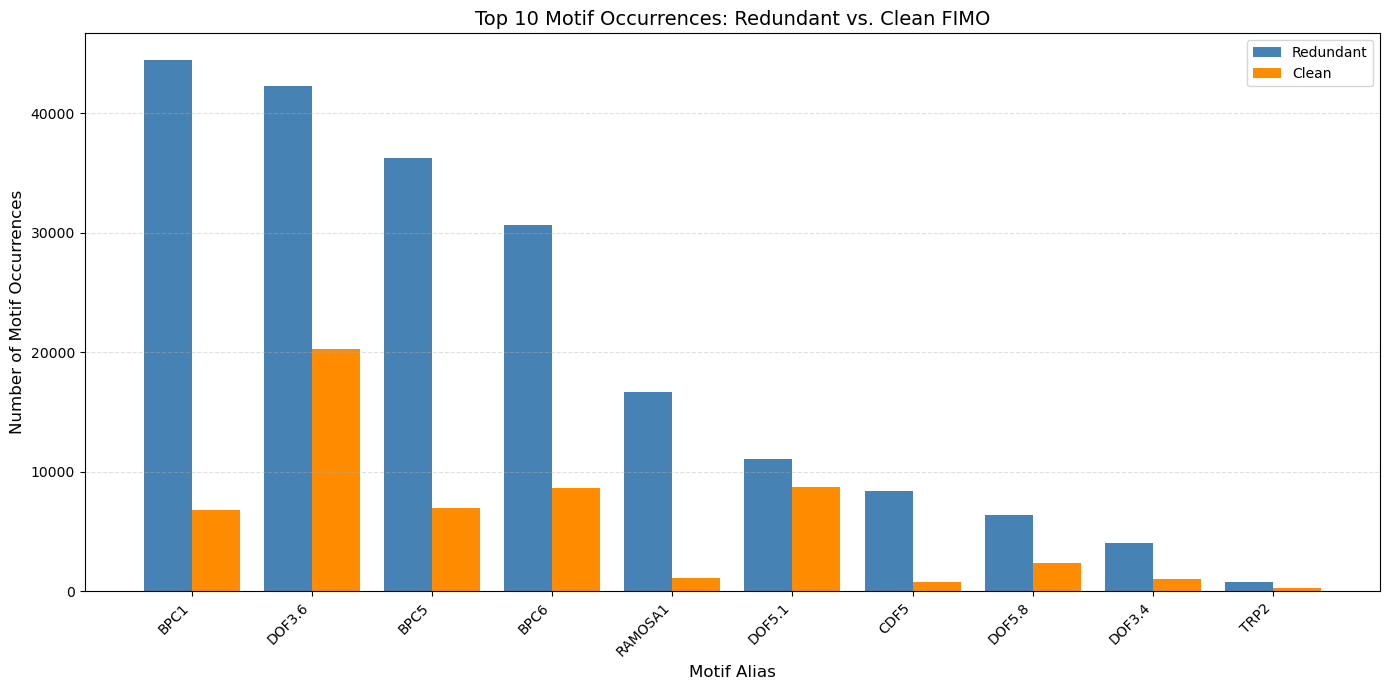


TOP 10 MOTIF OCCURRENCES
         Redundant  Clean
Alias                    
BPC1         44451   6803
DOF3.6       42255  20253
BPC5         36225   6933
BPC6         30594   8653
RAMOSA1      16662   1098
DOF5.1       11038   8714
CDF5          8382    732
DOF5.8        6374   2345
DOF3.4        4054    966
TRP2           792    228


In [17]:
##########################################################
# IMPORT AND PARSE CLEAN FIMO
##########################################################

clean_gff = pd.read_csv(
    "/Users/avery/fimo_collapsed_with_metadata.csv"
)

def extract_alias(attr):
    for field in attr.split(";"):
        if field.startswith("Alias="):
            return field.split("=")[1]
    return None

clean_gff["Alias"] = clean_gff["attributes"].apply(extract_alias)
clean_gff["sequence_id"] = clean_gff["seqid"].astype(str).str.strip()


##########################################################
# IMPORT AND PARSE REDUNDANT FIMO
##########################################################

redundant_gff = pd.read_csv(
    "/Users/avery/Downloads/fimo.gff",
    sep="\t",
    comment="#",
    header=None,
    names=[
        "seqid", "source", "type", "start", "end",
        "score", "strand", "phase", "attributes"
    ]
)

redundant_gff["Alias"] = redundant_gff["attributes"].apply(extract_alias)
redundant_gff["sequence_id"] = redundant_gff["seqid"].astype(str).str.strip()


##########################################################
# COUNT MOTIF OCCURRENCES
##########################################################

clean_counts = clean_gff["Alias"].value_counts()
redundant_counts = redundant_gff["Alias"].value_counts()

# Combine counts into one DataFrame for comparison
motif_counts = pd.DataFrame({
    "Redundant": redundant_counts,
    "Clean": clean_counts
}).fillna(0).astype(int)

# Select top 10 motifs based ONLY on redundant counts
top10 = motif_counts.nlargest(10, "Redundant")

# Sort by redundant counts
top10 = top10.sort_values("Redundant", ascending=False)

# Display results
print(top10)
##########################################################
# PLOT VERTICAL SIDE-BY-SIDE BAR CHART
##########################################################

x = np.arange(len(top10))
bar_width = 0.4

fig, ax = plt.subplots(figsize=(14, 7))

ax.bar(
    x - bar_width/2,
    top10["Redundant"],
    bar_width,
    label="Redundant",
    color="steelblue"
)

ax.bar(
    x + bar_width/2,
    top10["Clean"],
    bar_width,
    label="Clean",
    color="darkorange"
)

ax.set_xticks(x)
ax.set_xticklabels(top10.index, rotation=45, ha="right")

ax.set_xlabel("Motif Alias", fontsize=12)
ax.set_ylabel("Number of Motif Occurrences", fontsize=12)
ax.set_title(
    "Top 10 Motif Occurrences: Redundant vs. Clean FIMO",
    fontsize=14
)

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


##########################################################
# PRINT TOP 6 COUNTS
##########################################################

print("\nTOP 10 MOTIF OCCURRENCES")
print(top10.sort_values("Redundant", ascending=False))